In [68]:
import numpy as np
import pandas as pd
import re

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

#MachineLearning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv(r"C:\Users\maduo\Desktop\PDANA2\Assignment 2\book-prices-prediction\books_train.csv")
df.head()

,id,title,series,author,rating,description,language,isbn,genres,characters,...,publishDate,firstPublishDate,awards,numRatings,ratingsByStars,likedPercent,setting,bbeScore,bbeVotes,price
0,51689,"Henry IV, Part 2",Wars of the Roses #3,William Shakespeare,3.80,The stirring continuation of the themes begun ...,English,9.780550e+12,"['Plays', 'Classics', 'Drama', 'Historical Fic...","['Sir John Falstaff', 'Henry V of England', 'H...",...,January 1st 1988,1598,[],15769,"['4535', '5477', '4214', '1181', '362']",90.0,[],16,1,8.76
1,10676,A Bride Most Begrudging,NaN,Deeanne Gist (Goodreads Author),3.97,Any ship arriving from England means good news...,English,9.780760e+12,"['Christian Fiction', 'Historical Fiction', 'R...","['Drew O’Connor', 'Lady Constance Morrow', ""An...",...,July 1st 2005,01-01-2005,['Christy Award for Romance (2006)'],12704,"['4645', '4323', '2690', '771', '275']",92.0,['Virginia Colony (United States)'],226,3,1.92
2,42677,Parisians: An Adventure History of Paris,NaN,Graham Robb,3.67,"The secrets of the City of Light, revealed in ...",NaN,9.780390e+12,"['History', 'Nonfiction', 'France', 'Travel', ...","['Marcel Proust', 'Charles de Gaulle', 'Franço...",...,April 26th 2010,01-05-2010,['Stanford Dolman Travel Book of the Year Nomi...,2200,"['519', '765', '645', '214', '57']",88.0,['Paris (France)'],76,1,5.20
3,45383,With the Lightnings,Lt. Leary / RCN #1,David Drake,3.87,Daniel Leary is a lieutenant in the Republic o...,English,9.780670e+12,"['Science Fiction', 'Space Opera', 'Fiction', ...",[],...,July 1st 2000,11-06-1998,[],5826,"['1734', '2206', '1401', '363', '122']",92.0,[],66,1,2.86
4,45925,"Hand, Hand, Fingers, Thumb",NaN,"Al Perkins, Eric Gurney (Illustrator)",4.23,Illus. in full color. A madcap band of dancing...,English,9.780680e+12,"['Picture Books', 'Childrens', 'Fiction', 'Sto...",[],...,January 20th 1998,11-06-1969,[],28113,"['15088', '6560', '4715', '1250', '500']",94.0,[],64,1,5.68


In [3]:

# 1. Check the dataset dimensions
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Display the column names
print(df.columns.tolist())

# 3. Check data types and missing values
df.info()

Number of records: 26650
Number of columns: 24
['id', 'title', 'series', 'author', 'rating', 'description', 'language', 'isbn', 'genres', 'characters', 'bookFormat', 'edition', 'pages', 'publisher', 'publishDate', 'firstPublishDate', 'awards', 'numRatings', 'ratingsByStars', 'likedPercent', 'setting', 'bbeScore', 'bbeVotes', 'price']
<class 'pandas.DataFrame'>
RangeIndex: 26650 entries, 0 to 26649
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                26650 non-null  int64  
 1   title             26650 non-null  str    
 2   series            11741 non-null  str    
 3   author            26650 non-null  str    
 4   rating            26650 non-null  float64
 5   description       26237 non-null  str    
 6   language          25211 non-null  str    
 7   isbn              26650 non-null  float64
 8   genres            26650 non-null  str    
 9   characters        26650 non-null  str    
 1

The data has 24 columns with a total of 26 650 records.

In [4]:
df.describe(include="all")

,id,title,series,author,rating,description,language,isbn,genres,characters,...,publishDate,firstPublishDate,awards,numRatings,ratingsByStars,likedPercent,setting,bbeScore,bbeVotes,price
count,26650.000000,26650,11741,26650,26650.000000,26237,25211,2.665000e+04,26650,26650,...,26437,17616,26650,2.665000e+04,26650,26510.000000,26650,2.665000e+04,26650.000000,26650.000000
unique,NaN,25886,11517,16093,NaN,26192,50,NaN,24232,7389,...,7319,5504,5812,NaN,26106,NaN,2949,NaN,NaN,NaN
top,NaN,Selected Poems,Star Wars Legends,Nora Roberts (Goodreads Author),NaN,This is a pre-1923 historical reproduction tha...,English,NaN,[],[],...,Published,01-01-2010,[],NaN,[],NaN,[],NaN,NaN,NaN
freq,NaN,10,10,59,NaN,7,23460,NaN,1216,18667,...,120,130,20242,NaN,357,NaN,19949,NaN,NaN,NaN
mean,25784.429381,NaN,NaN,NaN,3.997118,NaN,NaN,9.776431e+12,NaN,NaN,...,NaN,NaN,NaN,1.948844e+04,NaN,92.279140,NaN,1.969132e+03,22.644278,9.704350
std,15579.238942,NaN,NaN,NaN,0.318197,NaN,NaN,2.159276e+11,NaN,NaN,...,NaN,NaN,NaN,9.446798e+04,NaN,5.467259,NaN,3.147227e+04,332.485114,25.067917
min,1.000000,NaN,NaN,NaN,0.000000,NaN,NaN,6.208427e+07,NaN,NaN,...,NaN,NaN,NaN,0.000000e+00,NaN,0.000000,NaN,0.000000e+00,-3.000000,0.840000
25%,11949.750000,NaN,NaN,NaN,3.810000,NaN,NaN,9.780380e+12,NaN,NaN,...,NaN,NaN,NaN,6.460000e+02,NaN,90.000000,NaN,8.300000e+01,1.000000,3.240000
50%,25668.000000,NaN,NaN,NaN,4.010000,NaN,NaN,9.780740e+12,NaN,NaN,...,NaN,NaN,NaN,3.219000e+03,NaN,93.000000,NaN,9.700000e+01,1.000000,5.220000
75%,39652.750000,NaN,NaN,NaN,4.190000,NaN,NaN,9.781470e+12,NaN,NaN,...,NaN,NaN,NaN,1.153375e+04,NaN,96.000000,NaN,1.950000e+02,2.000000,8.880000


This checks the structure of the book.
The data has 26 650 records, with 24 columns. Books in this dataset have an average rating of approximately 4/5. About 92% of the readers rated the books positively. Some columns have missing values.

In [5]:

# 1. Count missing values in each column
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

print("Columns containing missing values:")
display(missing_summary.to_frame(name="Missing Count"))

# 2. Calculate the percentage of missing values
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

display(
    missing_percentage[missing_percentage > 0]
    .to_frame(name="Missing Percentage (%)")
)

# 3. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 4. Check duplicate book IDs, if available
if "id" in df.columns:
    print("Duplicate book IDs:", df["id"].duplicated().sum())

# 5. Inspect the price column
if "price" in df.columns:
    print("\nPrice summary:")
    display(df["price"].describe())


Columns containing missing values:


,Missing Count
edition,24438
series,14909
firstPublishDate,9034
language,1439
pages,485
publisher,450
description,413
bookFormat,310
publishDate,213
likedPercent,140


,Missing Percentage (%)
edition,91.699812
series,55.943715
firstPublishDate,33.898687
language,5.399625
pages,1.819887
publisher,1.688555
description,1.549719
bookFormat,1.163227
publishDate,0.799250
likedPercent,0.525328


Duplicate rows: 0
Duplicate book IDs: 0

Price summary:


count    26650.000000
mean         9.704350
std         25.067917
min          0.840000
25%          3.240000
50%          5.220000
75%          8.880000
max        898.640000
Name: price, dtype: float64

It is noticeable from here that the edition column has quite a high number of missing values, about 92%, therefore it will be excluded as it has little useable information. More than half of the series values are missing which might suggest that a book does not belong to a series. The firstPublishDate has about 1/3 data missing, the publication year can be derived where available dates allow.


The price tags of the books has a median with a price of $9.70, and a median of $5.22. suggesting that that the distribution is right skewed. That is, a small number of expensive nooks are driving the mean upwards.

In [6]:
# Remove columns with extensive missing values
books = df.drop(columns=["edition", "series"])

# Check the remaining columns
print(books.columns.tolist())

# Check the shape of the dataset
print("Rows and columns:", books.shape)

['id', 'title', 'author', 'rating', 'description', 'language', 'isbn', 'genres', 'characters', 'bookFormat', 'pages', 'publisher', 'publishDate', 'firstPublishDate', 'awards', 'numRatings', 'ratingsByStars', 'likedPercent', 'setting', 'bbeScore', 'bbeVotes', 'price']
Rows and columns: (26650, 22)


The columns Edition and Series are therefore dropped as edition has 92% of the data missing and edition has more than half the data missing which would suggest that the books which have missing information on the series column are not a part of a series, and adding the series variable as a predictor would add complexity to the model.

From the available colums, the numratings column will be the target input features, it will be used to define the best seller proxy and excluded from the predictors. The potential predictors are rating, price,pages, language, bookFormat and PublishDate. Colums such as likedPercent, bbeVotes and bbeScore may be informative however could reflect popularity measured after publication.

In [7]:
# Count missing values in each remaining column
missing_counts = books.isnull().sum()

# Show only columns that have missing values
print(missing_counts[missing_counts > 0].sort_values(ascending=False))

firstPublishDate    9034
language            1439
pages                485
publisher            450
description          413
bookFormat           310
publishDate          213
likedPercent         140
dtype: int64


These are the columns that have missing values and this also shows how many values they have missing as well as which columns may need attention for investigation first, if we want to consider using the columns.

In [10]:
# Columns we are considering for our model
candidate_columns = [
    'language',
    'pages',
    'publisher',
    'bookFormat',
    'publishDate',
    'likedPercent',
    'rating',
    'numRatings',
    'bbeScore',
    'bbeVotes'
]

# Inspect data types and unique values
for column in candidate_columns:
    print(f"\nColumn: {column}")
    print("Data type:", books[column].dtype)
    print("Unique values:", books[column].nunique())


Column: language
Data type: str
Unique values: 50

Column: pages
Data type: str
Unique values: 1123

Column: publisher
Data type: str
Unique values: 5488

Column: bookFormat
Data type: str
Unique values: 72

Column: publishDate
Data type: str
Unique values: 7319

Column: likedPercent
Data type: float64
Unique values: 57

Column: rating
Data type: float64
Unique values: 237

Column: numRatings
Data type: int64
Unique values: 13652

Column: bbeScore
Data type: int64
Unique values: 2543

Column: bbeVotes
Data type: int64
Unique values: 457


The considered colums for the model. This investigates their data type as well as the unique values. From the considered columns, the model will use language, pages, price, rating, bookformat and publishDate.

In [12]:
# Display 30 examples of publication dates
print(books['publishDate'].head(30).to_string(index=False))

   January 1st 1988
      July 1st 2005
    April 26th 2010
      July 1st 2000
  January 20th 1998
 February 25th 1999
     June 15th 2010
 February 13th 2009
   January 6th 2004
       May 1st 2002
 February 26th 2015
  December 3rd 2019
             Jul-08
     June 15th 1998
    March 27th 2007
         08-07-2001
  January 15th 2009
  January 20th 2004
 December 31st 2006
             Mar-10
       May 1st 2010
  January 14th 2015
September 30th 2014
   January 5th 2000
  October 10th 2000
  February 1st 2003
     March 1st 2010
 September 3rd 2013
         03-01-1989
     June 16th 2015


In [13]:
# Display the 20 most common publication dates
print(books['publishDate'].value_counts(dropna=False).head(20))

publishDate
NaN                   213
Published             120
2006                   77
2001                   72
May 1st 2007           72
2005                   70
2003                   70
2004                   66
2010                   63
2008                   62
2009                   57
2011                   55
September 1st 2009     53
2007                   50
2000                   47
2002                   46
1999                   44
January 1st 2006       44
November 1st 2005      43
September 1st 2004     43
Name: count, dtype: int64


Since publishDate is considered as one of the columns to use for the model, the column is investigated to see the different formats in the columns as well as seeing if there are missing values. The goal for this column is to extract the year in which a book was published.

In [15]:
# Extract the publication year from each date
def extract_year(date):
    # Handle missing values
    if pd.isna(date):
        return pd.NA

    date = str(date).strip()

    # Ignore uninformative text
    if date.lower() == "published" or date == "":
        return pd.NA

    # Extract a four-digit year wherever it appears
    year_match = re.search(r'\b(1[0-9]{3}|20[0-9]{2})\b', date)

    if year_match:
        return int(year_match.group(1))

    # Handle abbreviated month-year formats such as Jul-08
    try:
        parsed_date = pd.to_datetime(
            date, format="%b-%y", errors="raise"
        )
        return parsed_date.year
    except (ValueError, TypeError):
        return pd.NA


# Create a new column without changing the original dates
books['publish_year'] = books['publishDate'].apply(extract_year)

# Display examples to verify the results
print(books[['publishDate', 'publish_year']].head(30).to_string(index=False))


        publishDate publish_year
   January 1st 1988         1988
      July 1st 2005         2005
    April 26th 2010         2010
      July 1st 2000         2000
  January 20th 1998         1998
 February 25th 1999         1999
     June 15th 2010         2010
 February 13th 2009         2009
   January 6th 2004         2004
       May 1st 2002         2002
 February 26th 2015         2015
  December 3rd 2019         2019
             Jul-08         2008
     June 15th 1998         1998
    March 27th 2007         2007
         08-07-2001         2001
  January 15th 2009         2009
  January 20th 2004         2004
 December 31st 2006         2006
             Mar-10         2010
       May 1st 2010         2010
  January 14th 2015         2015
September 30th 2014         2014
   January 5th 2000         2000
  October 10th 2000         2000
  February 1st 2003         2003
     March 1st 2010         2010
 September 3rd 2013         2013
         03-01-1989         1989
     June 

Create a publish_Year column which stores the extracted years of the publish dates.

In [16]:
# Count successfully extracted years and remaining missing values
print("Successfully extracted years:", books['publish_year'].notna().sum())
print("Missing publication years:", books['publish_year'].isna().sum())

# Inspect the distribution of publication years
print("\nMost frequent publication years:")
print(books['publish_year'].value_counts().sort_index().to_string())


Successfully extracted years: 26024
Missing publication years: 626

Most frequent publication years:
publish_year
1000       1
1900       2
1911       1
1920       1
1925       1
1926       2
1927       1
1931       1
1934       1
1936       1
1937       2
1939       1
1941       2
1942       1
1945       1
1948       1
1949       2
1950       3
1951       2
1952       4
1953       2
1954       6
1955       4
1956       2
1957       4
1958       4
1959       9
1960       4
1961       7
1962       9
1963       9
1964      15
1965      13
1966      18
1967      20
1968      22
1969      30
1970      15
1971      31
1972      42
1973      38
1974      40
1975      37
1976      39
1977      55
1978      55
1979      51
1980      57
1981      66
1982      68
1983      96
1984      97
1985     115
1986     129
1987     136
1988     180
1989     179
1990     206
1991     236
1992     260
1993     297
1994     344
1995     383
1996     403
1997     450
1998     530
1999     639
2000     654
20

In [17]:

# Inspect original dates associated with unusual years
unusual_years = [1000, 2036, 2040, 2056, 2060, 2063, 2064, 2065]

for year in unusual_years:
    print(f"\nPublication year: {year}")

    print(
        books.loc[
            books['publish_year'].eq(year),
            'publishDate'
        ].to_string(index=False)
    )



Publication year: 1000
Finland\n\n42 books — 27 voters\n1000 vuotta - ...

Publication year: 2036
Apr-36

Publication year: 2040
Jun-40

Publication year: 2056
Nov-56

Publication year: 2060
Feb-60

Publication year: 2063
Jan-63

Publication year: 2064
Jan-64
Dec-64
Sep-64
Dec-64

Publication year: 2065
Oct-65
Dec-65


From here we can establish that year 1000 was a false positive and the entry was mainly text and the other future dates were actually a century-parsing error, the years belong to the 1900, So instead of 2036 it would be 1936.

In [18]:
# 1. Correct abbreviated month-year dates

month_year_pattern = (
    r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-(\d{2})$'
)

# Identify dates written as Mon-YY
month_year_mask = books['publishDate'].str.strip().str.match(
    month_year_pattern,
    case=False,
    na=False
)

# Extract the two-digit year
year_suffix = (
    books.loc[month_year_mask, 'publishDate']
    .str.strip()
    .str.extract(month_year_pattern, flags=0)[1]
    .astype(int)
)

# Apply our agreed century rule:
# 00–26 = 2000–2026
# 27–99 = 1927–1999
books.loc[month_year_mask, 'publish_year'] = year_suffix.apply(
    lambda year: 2000 + year if year <= 26 else 1900 + year
)

# 2. Remove the false publication year 1000
# It was extracted from descriptive text, not a publication date.

false_year_mask = (
    books['publish_year'].eq(1000)
    & books['publishDate'].str.contains(
        r'1000\s+vuotta',
        case=False,
        na=False
    )
)

books.loc[false_year_mask, 'publish_year'] = pd.NA

# 3. Check the corrections
print("Corrected publication years:")

print(
    books.loc[
        books['publishDate'].str.strip().str.match(
            month_year_pattern,
            case=False,
            na=False
        ),
        ['publishDate', 'publish_year']
    ].sort_values('publishDate').to_string(index=False)
)

print("\nRemaining suspicious years:")

print(
    books.loc[
        books['publish_year'].isin(
            [1000, 2036, 2040, 2056, 2060, 2063, 2064, 2065]
        ),
        ['publishDate', 'publish_year']
    ].to_string(index=False)
)

print("\nKnown publication years:", books['publish_year'].notna().sum())
print("Missing publication years:", books['publish_year'].isna().sum())

Corrected publication years:
publishDate publish_year
     Apr-00         2000
     Apr-00         2000
     Apr-01         2001
     Apr-02         2002
     Apr-03         2003
     Apr-03         2003
     Apr-03         2003
     Apr-03         2003
     Apr-04         2004
     Apr-04         2004
     Apr-04         2004
     Apr-05         2005
     Apr-05         2005
     Apr-05         2005
     Apr-05         2005
     Apr-05         2005
     Apr-06         2006
     Apr-06         2006
     Apr-07         2007
     Apr-08         2008
     Apr-08         2008
     Apr-09         2009
     Apr-09         2009
     Apr-10         2010
     Apr-11         2011
     Apr-11         2011
     Apr-11         2011
     Apr-11         2011
     Apr-11         2011
     Apr-12         2012
     Apr-12         2012
     Apr-12         2012
     Apr-13         2013
     Apr-13         2013
     Apr-15         2015
     Apr-16         2016
     Apr-17         2017
     Apr-36         1

In [19]:
# 1. Summary statistics for publication years
print("Publication year summary:")
print(books['publish_year'].describe())

# 2. Check the earliest and latest publication years
print("\n10 earliest publication years:")
print(
    books.loc[
        books['publish_year'].notna(),
        ['title', 'publishDate', 'publish_year']
    ]
    .sort_values('publish_year')
    .head(10)
    .to_string(index=False)
)

print("\n10 latest publication years:")
print(
    books.loc[
        books['publish_year'].notna(),
        ['title', 'publishDate', 'publish_year']
    ]
    .sort_values('publish_year', ascending=False)
    .head(10)
    .to_string(index=False)
)

# 3. Count years outside our initial plausible range
print("\nYears before 1400:")
print((books['publish_year'] < 1400).sum())

print("\nYears after 2026:")
print((books['publish_year'] > 2026).sum())

# 4. Inspect missing publication dates
print("\nMissing publication year examples:")
print(
    books.loc[
        books['publish_year'].isna(),
        ['title', 'publishDate']
    ].head(15).to_string(index=False)
)

Publication year summary:
count     26023
unique       88
top        2006
freq       1641
Name: publish_year, dtype: int64

10 earliest publication years:
                                                                                                                                                   title       publishDate publish_year
                                                                                                                                         More Max Danger  January 1st 1900         1900
                                                                                                         Max Danger: The Adventures of an Expat in Tokyo  January 1st 1900         1900
The Rosicrucian cosmo-conception: or, Mystic Christianity; an elementary treatise upon man's past evolution, present constitution and future development              1911         1911
                                                                                                             

In [20]:
# Recover publication years from MM/DD/YY dates

import pandas as pd

# Work only with rows whose publication year is missing
raw_dates = books['publishDate'].astype('string').str.strip()

missing_year_mask = books['publish_year'].isna()

slash_date_mask = raw_dates.str.fullmatch(
    r'\d{1,2}/\d{1,2}/\d{2}',
    na=False
)

recover_mask = missing_year_mask & slash_date_mask

# Extract month, day, and two-digit year
date_parts = raw_dates.loc[recover_mask].str.extract(
    r'^(\d{1,2})/(\d{1,2})/(\d{2})$'
)

month = date_parts[0].astype(int)
day = date_parts[1].astype(int)
year_suffix = date_parts[2].astype(int)

# Apply the same century rule used previously
full_year = year_suffix.where(
    year_suffix <= 26,
    year_suffix + 1900
)

full_year = full_year.where(
    year_suffix > 26,
    year_suffix + 2000
)

# Validate that each date actually exists
candidate_dates = (
    full_year.astype(str)
    + '-'
    + month.astype(str).str.zfill(2)
    + '-'
    + day.astype(str).str.zfill(2)
)

valid_dates = pd.to_datetime(
    candidate_dates,
    format='%Y-%m-%d',
    errors='coerce'
)

# Fill only missing years with valid dates
valid_mask = valid_dates.notna()

books.loc[
    valid_dates.index[valid_mask],
    'publish_year'
] = full_year.loc[valid_mask].astype(int).astype(str)

# Convert the complete year column to a consistent numeric type
books['publish_year'] = pd.to_numeric(
    books['publish_year'],
    errors='coerce'
).astype('Int64')

# Report the results
print("Recovered years:", int(valid_mask.sum()))
print("Known publication years:", int(books['publish_year'].notna().sum()))
print("Missing publication years:", int(books['publish_year'].isna().sum()))

print("\nRecovered dates:")
print(
    books.loc[
        valid_dates.index[valid_mask],
        ['title', 'publishDate', 'publish_year']
    ].to_string(index=False)
)

print("\nUpdated numeric summary:")
print(books['publish_year'].describe())

Recovered years: 243
Known publication years: 26266
Missing publication years: 384

Recovered dates:
                                                                                            title publishDate  publish_year
                                                                                A Game of Thrones    08/28/05          2005
                                                       Matching Configurations: QUANTUM ROOTS III    03/25/19          2019
                                                                                        Crescendo    10/19/10          2010
                                                                                Different Seasons    02/16/95          1995
                                                                                     East of Eden    10/28/02          2002
                                                                                           Finale    10/23/12          2012
                               

In [31]:
# Inspect the remaining unresolved publication dates

missing_dates = books.loc[
    books['publish_year'].isna(),
    ['title', 'publishDate']
].copy()

print("Remaining missing years:", len(missing_dates))

print("\nMost frequent unresolved date values:")
print(
    missing_dates['publishDate']
    .fillna('[Missing]')
    .value_counts()
    .head(30)
    .to_string()
)

print("\nExamples of unresolved values:")
print(missing_dates.head(25).to_string(index=False))

Remaining missing years: 384

Most frequent unresolved date values:
publishDate
[Missing]                                                                                                                                    213
Published                                                                                                                                    120
Books I will make my children read\n\n93 books — 26 voters\nMorrissey & The Smiths\n\n67 books — 33 voters                                     1
Unsung Works of Genius\n\n279 books — 46 voters\nSerious                                                                                       1
October 4th 13                                                                                                                                 1
Finland\n\n42 books — 27 voters\n1000 vuotta - 100 kirjaa\n\n98 books — 6 voters                                                               1
Best LDS fiction\n\n568 books — 476 voters\nBest o

In [32]:
print("Data type:", books['publish_year'].dtype)

print("\nMissing years:", books['publish_year'].isna().sum())

print("\nUnique publication years:")
print(sorted(books['publish_year'].dropna().unique().tolist()))

Data type: Int64

Missing years: 384

Unique publication years:
[1900, 1911, 1920, 1925, 1926, 1927, 1931, 1934, 1936, 1937, 1939, 1940, 1941, 1942, 1945, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]


In [22]:
books['publish_year_status'] = books['publish_year'].apply(
    lambda year: 'Unknown' if pd.isna(year) else 'Known'
)

print(books['publish_year_status'].value_counts())

publish_year_status
Known      26266
Unknown      384
Name: count, dtype: int64


And finally, for publish year, we have 26266 known dates and 384 unknown.

In [33]:
print(
    books.loc[
        books['publish_year'] == 1900,
        ['title', 'publishDate', 'publish_year']
    ].to_string(index=False)
)

                                          title      publishDate  publish_year
Max Danger: The Adventures of an Expat in Tokyo January 1st 1900          1900
                                More Max Danger January 1st 1900          1900


In [27]:
# Calculate the 80th-percentile threshold
threshold = books['numRatings'].quantile(0.80)

# Create the target variable
books['bestseller'] = (
    books['numRatings'] >= threshold
).astype(int)

# Display the results
print("Bestseller threshold:", threshold)

print("\nTarget distribution:")
print(books['bestseller'].value_counts())

print("\nTarget distribution (%):")
print(
    (books['bestseller'].value_counts(normalize=True) * 100).round(2)
)

Bestseller threshold: 15469.000000000004

Target distribution:
bestseller
0    21320
1     5330
Name: count, dtype: int64

Target distribution (%):
bestseller
0    80.0
1    20.0
Name: proportion, dtype: float64


In [28]:
# Select the variables for our model
features = [
    'rating',
    'price',
    'likedPercent',
    'pages',
    'publish_year',
    'language',
    'bookFormat'
]

# Check the selected columns
print("Dataset shape:", books.shape)

print("\nMissing values in selected features:")
print(books[features].isna().sum())

print("\nTarget distribution:")
print(books['bestseller'].value_counts())

Dataset shape: (26650, 25)

Missing values in selected features:
rating             0
price              0
likedPercent     140
pages            485
publish_year     384
language        1439
bookFormat       310
dtype: int64

Target distribution:
bestseller
0    21320
1     5330
Name: count, dtype: int64


In [29]:
print(books[
    ['rating', 'price', 'likedPercent', 'pages', 'publish_year']
].dtypes)

rating          float64
price           float64
likedPercent    float64
pages               str
publish_year      Int64
dtype: object


In [30]:
# Convert page counts to numeric values
books['pages'] = pd.to_numeric(
    books['pages'],
    errors='coerce'
)

# Check the results
print("Pages data type:", books['pages'].dtype)
print("Missing page counts:", books['pages'].isna().sum())

print("\nPage count summary:")
print(books['pages'].describe())

Pages data type: float64
Missing page counts: 496

Page count summary:
count    26154.000000
mean       338.387168
std        243.217653
min          0.000000
25%        224.000000
50%        314.000000
75%        400.000000
max      14777.000000
Name: pages, dtype: float64


Book page data type is turned to numeric.

In [34]:
# Inspect books with zero pages
print("Books with zero pages:")
print(
    books.loc[
        books['pages'] == 0,
        ['title', 'pages']
    ].head(10).to_string(index=False)
)

# Inspect books with unusually high page counts
print("\nBooks with more than 2,000 pages:")
print(
    books.loc[
        books['pages'] > 2000,
        ['title', 'pages']
    ].sort_values('pages', ascending=False).head(15).to_string(index=False)
)

Books with zero pages:
                         title  pages
             The Road Winds On    0.0
Letter to My Daughter: A Novel    0.0
         The Wanting of Levine    0.0
                       Wildcat    0.0
    The Egyptian Cross Mystery    0.0
                 The Reckoning    0.0
               Love is Eternal    0.0
       Lady Here's Your Wreath    0.0
          The Chessmen of Mars    0.0
      One, Two, Buckle My Shoe    0.0

Books with more than 2,000 pages:
                                                                                                                                                         title   pages
                                                                                                                                     The Story of Civilization 14777.0
                                                                                                                                    The Complete Wheel of Time 11095.0
                       

The are books with zero pages which is a little inconsistent as a published books should have atleast one page. So it is either this is an entry error or the pages are unknown. The books with more than 2000 pages are box sets, complete collections, encyclopedias, or multi-volume works.

In [35]:
# Replace zero page counts with missing values
books.loc[books['pages'] == 0, 'pages'] = float('nan')

# Verify the change
print("Zero page counts remaining:", (books['pages'] == 0).sum())
print("Missing page counts:", books['pages'].isna().sum())

print("\nUpdated page count summary:")
print(books['pages'].describe())

Zero page counts remaining: 0
Missing page counts: 545

Updated page count summary:
count    26105.000000
mean       339.022333
std        243.003134
min          2.000000
25%        224.000000
50%        315.000000
75%        400.000000
max      14777.000000
Name: pages, dtype: float64


In [36]:
# Check numerical feature data types
print("Numerical feature data types:")
print(
    books[
        ['rating', 'price', 'likedPercent', 'pages', 'publish_year']
    ].dtypes
)

# Check missing values
print("\nMissing values:")
print(
    books[
        ['rating', 'price', 'likedPercent', 'pages', 'publish_year']
    ].isna().sum()
)

# Check for invalid zero or negative prices
print("\nZero or negative prices:", (books['price'] <= 0).sum())

Numerical feature data types:
rating          float64
price           float64
likedPercent    float64
pages           float64
publish_year      Int64
dtype: object

Missing values:
rating            0
price             0
likedPercent    140
pages           545
publish_year    384
dtype: int64

Zero or negative prices: 0


In [37]:
# Summary statistics for likedPercent
print("LikedPercent summary:")
print(books['likedPercent'].describe())

# Count missing values
print("\nMissing values:", books['likedPercent'].isna().sum())

# Check values outside the valid percentage range
invalid_likes = books[
    (books['likedPercent'] < 0) |
    (books['likedPercent'] > 100)
]

print("\nValues outside 0–100:", len(invalid_likes))

if len(invalid_likes) > 0:
    print(invalid_likes[['title', 'likedPercent']].head(10))

LikedPercent summary:
count    26510.000000
mean        92.279140
std          5.467259
min          0.000000
25%         90.000000
50%         93.000000
75%         96.000000
max        100.000000
Name: likedPercent, dtype: float64

Missing values: 140

Values outside 0–100: 0


No values falling outside the 0-100%, 

In [38]:
# Compare books with and without likedPercent values
books['likedPercent_missing'] = books['likedPercent'].isna()

print(
    books.groupby('likedPercent_missing')['numRatings']
    .agg(['count', 'median', 'mean'])
)

print("\nBestseller distribution for missing likedPercent:")
print(
    books.loc[
        books['likedPercent_missing'],
        'bestseller'
    ].value_counts()
)

                      count  median          mean
likedPercent_missing                             
False                 26510  3259.0  19591.345605
True                    140     2.0      2.328571

Bestseller distribution for missing likedPercent:
bestseller
0    140
Name: count, dtype: int64


In [39]:
print("Rating summary:")
print(books['rating'].describe())

print("\nRatings outside 0–5:")
print(
    books.loc[
        (books['rating'] < 0) | (books['rating'] > 5),
        ['title', 'rating']
    ]
)

print("\nBooks with a rating of zero:")
print(
    books.loc[
        books['rating'] == 0,
        ['title', 'rating', 'numRatings']
    ].head(10).to_string(index=False)
)

print("\nTotal zero ratings:", (books['rating'] == 0).sum())

Rating summary:
count    26650.000000
mean         3.997118
std          0.318197
min          0.000000
25%          3.810000
50%          4.010000
75%          4.190000
max          5.000000
Name: rating, dtype: float64

Ratings outside 0–5:
Empty DataFrame
Columns: [title, rating]
Index: []

Books with a rating of zero:
                                                                                                                                   title  rating  numRatings
                                                                                     Princess Diana Life After Death of the English Rose     0.0           0
                                                                       Fatal Choice: Nuclear Weapons And The Illusion Of Missile Defense     0.0           0
Mach Deine Träume Wahrverwirkliche Deine Ziele Durch Die Kraft Deiner Gedanken, Deiner Gefühle Und Deines Verhaltens ; Die "3 G Methode"     0.0           0
                                                

There are no rating falling outside the 0-5 rating, The books with zero rating may be books with that are unrated rather than a genuine average rating. The 13 zero ratings will be converted to missing values. 

In [40]:
# Replace zero ratings with missing values
books.loc[books['rating'] == 0, 'rating'] = float('nan')

# Verify the changes
print("Missing ratings:", books['rating'].isna().sum())
print("Zero ratings remaining:", (books['rating'] == 0).sum())

print("\nUpdated rating summary:")
print(books['rating'].describe())

Missing ratings: 13
Zero ratings remaining: 0

Updated rating summary:
count    26637.000000
mean         3.999069
std          0.305774
min          1.000000
25%          3.810000
50%          4.010000
75%          4.190000
max          5.000000
Name: rating, dtype: float64


In [41]:
# Summary statistics for book prices
print("Price summary:")
print(books['price'].describe())

# Check for missing prices
print("\nMissing prices:", books['price'].isna().sum())

# Check for zero or negative prices
print("Zero prices:", (books['price'] == 0).sum())
print("Negative prices:", (books['price'] < 0).sum())

# Inspect the 10 most expensive books
print("\n10 most expensive books:")
print(
    books.nlargest(10, 'price')[['title', 'price']]
    .to_string(index=False)
)

Price summary:
count    26650.000000
mean         9.704350
std         25.067917
min          0.840000
25%          3.240000
50%          5.220000
75%          8.880000
max        898.640000
Name: price, dtype: float64

Missing prices: 0
Zero prices: 0
Negative prices: 0

10 most expensive books:
                                                                               title  price
                                                                  I See by My Outfit 898.64
Margin of Safety: Risk-Averse Value Investing Strategies for the Thoughtful Investor 867.05
                                                V/Crying of Lot 49/Gravity's Rainbow 811.04
                   Men's Garments, 1830-1900: Guide to Pattern Cutting and Tailoring 796.14
                                                                             Progeny 777.35
                                                                    Children of Time 711.55
          My Year in Oman: An American Experience in Arabi

The prices are right skewed as seen from the summary results, the median price is 5.22 and the mean is 9.70, the 99th percentile is 86.295 compared to the maximum of 898.64, and in this case the maximum is ~172 times the meadian.

The extreme upper tail could influence the Logistic Regression and so the price feature is transformed rather than automatically removing them.

In [42]:
# Calculate the interquartile range
Q1 = books['price'].quantile(0.25)
Q3 = books['price'].quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper outlier threshold
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers
price_outliers = books[books['price'] > upper_limit]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier limit:", upper_limit)

print("\nPotential price outliers:", len(price_outliers))
print("Percentage of dataset:", round(len(price_outliers) / len(books) * 100, 2), "%")

print("\nHighest prices among the outliers:")
print(
    price_outliers.nlargest(10, 'price')[['title', 'price']]
    .to_string(index=False)
)

Q1: 3.24
Q3: 8.88
IQR: 5.640000000000001
Upper outlier limit: 17.340000000000003

Potential price outliers: 2468
Percentage of dataset: 9.26 %

Highest prices among the outliers:
                                                                               title  price
                                                                  I See by My Outfit 898.64
Margin of Safety: Risk-Averse Value Investing Strategies for the Thoughtful Investor 867.05
                                                V/Crying of Lot 49/Gravity's Rainbow 811.04
                   Men's Garments, 1830-1900: Guide to Pattern Cutting and Tailoring 796.14
                                                                             Progeny 777.35
                                                                    Children of Time 711.55
          My Year in Oman: An American Experience in Arabia During the War on Terror 636.27
                                                               Revolutionary Letters 

From here it is noticeable that there are 2468 outliers pulling the average price really higher, and so the prices are strongly right skewed, so it is worth considering the log transformation before standardization.

In [43]:
numerical_features = [
    'rating',
    'price',
    'likedPercent',
    'pages',
    'publish_year'
]

print("Missing values:")
print(books[numerical_features].isna().sum())

print("\nData types:")
print(books[numerical_features].dtypes)

Missing values:
rating           13
price             0
likedPercent    140
pages           545
publish_year    384
dtype: int64

Data types:
rating          float64
price           float64
likedPercent    float64
pages           float64
publish_year      Int64
dtype: object


NEXT: CATEGORICAL PREDICTORS

In [44]:
categorical_features = ['language', 'bookFormat']

for column in categorical_features:
    print(f"\n--- {column} ---")
    print("Missing values:", books[column].isna().sum())
    print("Unique categories:", books[column].nunique())

    print("\nMost frequent categories:")
    print(books[column].value_counts(dropna=False).head(10))


--- language ---
Missing values: 1439
Unique categories: 50

Most frequent categories:
language
English       23460
NaN            1439
Spanish         378
French          345
German          314
Italian         130
Portuguese      105
Dutch            76
Turkish          74
Arabic           61
Name: count, dtype: int64

--- bookFormat ---
Missing values: 310
Unique categories: 72

Most frequent categories:
bookFormat
Paperback                16061
Hardcover                 7680
Mass Market Paperback     1697
Kindle Edition             436
NaN                        310
Audio CD                    74
ebook                       73
Unknown Binding             63
Trade Paperback             36
Audiobook                   24
Name: count, dtype: int64


In [45]:
# Check for leading or trailing whitespace
for column in ['language', 'bookFormat']:
    values = books[column].dropna().astype(str)

    whitespace_count = (
        values != values.str.strip()
    ).sum()

    print(f"\n{column}")
    print("Values with extra whitespace:", whitespace_count)

    print("\nCategories:")
    print(sorted(values.unique().tolist()))


language
Values with extra whitespace: 0

Categories:
['Afrikaans', 'Aleut', 'Arabic', 'Basque', 'Bengali', 'Bulgarian', 'Catalan; Valencian', 'Chinese', 'Croatian', 'Czech', 'Danish', 'Duala', 'Dutch', 'English', 'Estonian', 'Faroese', 'Filipino; Pilipino', 'Finnish', 'French', 'Galician', 'Georgian', 'German', 'Greek, Modern (1453-)', 'Hindi', 'Hungarian', 'Indonesian', 'Italian', 'Japanese', 'Korean', 'Kurdish', 'Latvian', 'Lithuanian', 'Malay', 'Malayalam', 'Marathi', 'Mayan languages', 'Multiple languages', 'Norwegian', 'Persian', 'Polish', 'Portuguese', 'Romanian', 'Russian', 'Serbian', 'Spanish', 'Swedish', 'Tamil', 'Turkish', 'Urdu', 'Vietnamese']

bookFormat
Values with extra whitespace: 4

Categories:
['Album', 'Audible Audio', 'Audio', 'Audio CD', 'Audio Cassette', 'Audio Cd', 'Audio Play', 'Audiobook', 'Bantam New Fiction', 'Big Book', 'Board', 'Board Book', 'Board book', 'Bolsillo con sobrecubierta', 'Bonded Leather', 'Box Set', 'Boxed Set', 'Broché', 'Broschiert', 'Bìa m

In [46]:
# Remove leading and trailing whitespace
books['bookFormat'] = books['bookFormat'].str.strip()

# Standardise known spelling and capitalisation variations
format_corrections = {
    'Audio Cd': 'Audio CD',
    'Board book': 'Board Book',
    'Hardcover': 'Hardcover',
    'hardcover': 'Hardcover',
    'paperback': 'Paperback',
    'Paperback': 'Paperback',
    'Mass Market Paperback': 'Mass Market Paperback',
    'mass_market': 'Mass Market Paperback',
    'paper': 'Paperback',
    'softcover': 'Paperback',
    'cloth': 'Hardcover',
    'Unknown Binding': 'Unknown'
}

books['bookFormat'] = books['bookFormat'].replace(format_corrections)

# Replace missing book formats with Unknown
books['bookFormat'] = books['bookFormat'].fillna('Unknown')

# Check the results
print("Missing bookFormat values:", books['bookFormat'].isna().sum())
print("\nMost frequent book formats:")
print(books['bookFormat'].value_counts().head(15))

print("\nRemaining categories:")
print(sorted(books['bookFormat'].unique().tolist()))

Missing bookFormat values: 0

Most frequent book formats:
bookFormat
Paperback                16083
Hardcover                 7687
Mass Market Paperback     1700
Kindle Edition             436
Unknown                    373
Audio CD                    75
ebook                       73
Trade Paperback             36
Audiobook                   24
Board Book                  20
Library Binding             16
Audible Audio               11
Leather Bound               10
Comics                       9
Audio Cassette               8
Name: count, dtype: int64

Remaining categories:
['Album', 'Audible Audio', 'Audio', 'Audio CD', 'Audio Cassette', 'Audio Play', 'Audiobook', 'Bantam New Fiction', 'Big Book', 'Board', 'Board Book', 'Bolsillo con sobrecubierta', 'Bonded Leather', 'Box Set', 'Boxed Set', 'Broché', 'Broschiert', 'Bìa mềm', 'CD-ROM', 'Capa Mole', 'Capa comum', 'Capa dura', 'Capa mole', 'Casebound', 'Comics', 'Diary', 'Digital', 'Graphic Novels', 'Hardback', 'Hardcover', 'Hardcover 

In [47]:
# Replace missing language values with Unknown
books['language'] = books['language'].fillna('Unknown')

# Verify both categorical columns
print("Missing language values:", books['language'].isna().sum())
print("Missing bookFormat values:", books['bookFormat'].isna().sum())

Missing language values: 0
Missing bookFormat values: 0


In [48]:
# Check the cleaned categorical columns
for column in ['language', 'bookFormat']:
    print(f"\n--- {column} ---")
    print("Missing values:", books[column].isna().sum())
    print("Number of categories:", books[column].nunique())
    print("\nMost frequent categories:")
    print(books[column].value_counts().head(10))


--- language ---
Missing values: 0
Number of categories: 51

Most frequent categories:
language
English       23460
Unknown        1439
Spanish         378
French          345
German          314
Italian         130
Portuguese      105
Dutch            76
Turkish          74
Arabic           61
Name: count, dtype: int64

--- bookFormat ---
Missing values: 0
Number of categories: 62

Most frequent categories:
bookFormat
Paperback                16083
Hardcover                 7687
Mass Market Paperback     1700
Kindle Edition             436
Unknown                    373
Audio CD                    75
ebook                       73
Trade Paperback             36
Audiobook                   24
Board Book                  20
Name: count, dtype: int64


In [49]:
# Select the predictor columns
feature_columns = [
    'rating',
    'price',
    'likedPercent',
    'pages',
    'publish_year',
    'language',
    'bookFormat'
]

# Create the feature dataset and target
X = books[feature_columns].copy()
y = books['bestseller'].copy()

# Check the results
print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values in selected features:")
print(X.isna().sum())

Feature dataset shape: (26650, 7)
Target shape: (26650,)

Feature columns:
['rating', 'price', 'likedPercent', 'pages', 'publish_year', 'language', 'bookFormat']

Target distribution:
bestseller
0    21320
1     5330
Name: count, dtype: int64

Missing values in selected features:
rating           13
price             0
likedPercent    140
pages           545
publish_year    384
language          0
bookFormat        0
dtype: int64


NEXT: DATA SPLIT

In [50]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (21320, 7)
Testing features: (5330, 7)

Training target distribution:
bestseller
0    17056
1     4264
Name: count, dtype: int64

Testing target distribution:
bestseller
0    4264
1    1066
Name: count, dtype: int64


In [51]:
# Identify numerical predictors
numerical_columns = [
    'rating',
    'price',
    'likedPercent',
    'pages',
    'publish_year'
]

# Calculate medians using the training set only
training_medians = X_train[numerical_columns].median()

print("Training-set medians:")
print(training_medians)

# Fill missing numerical values in training and testing sets
X_train[numerical_columns] = X_train[numerical_columns].fillna(
    training_medians
)

X_test[numerical_columns] = X_test[numerical_columns].fillna(
    training_medians
)

# Verify that no numerical missing values remain
print("\nMissing numerical values in training set:")
print(X_train[numerical_columns].isna().sum())

print("\nMissing numerical values in testing set:")
print(X_test[numerical_columns].isna().sum())

Training-set medians:
rating             4.0
price             5.22
likedPercent      93.0
pages            315.0
publish_year    2007.0
dtype: Float64

Missing numerical values in training set:
rating          0
price           0
likedPercent    0
pages           0
publish_year    0
dtype: int64

Missing numerical values in testing set:
rating          0
price           0
likedPercent    0
pages           0
publish_year    0
dtype: int64


In [52]:

# One-hot encode categorical predictors
categorical_columns = ['language', 'bookFormat']

X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    dtype=int
)

# Ensure both datasets have exactly the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Check the results
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("\nDo the columns match?")
print(X_train_encoded.columns.equals(X_test_encoded.columns))

print("\nFirst 10 encoded column names:")
print(X_train_encoded.columns[:10].tolist())

Encoded training shape: (21320, 109)
Encoded testing shape: (5330, 109)

Do the columns match?
True

First 10 encoded column names:
['rating', 'price', 'likedPercent', 'pages', 'publish_year', 'language_Afrikaans', 'language_Aleut', 'language_Arabic', 'language_Basque', 'language_Bengali']


In [53]:
# Identify numerical columns to scale
numerical_columns = [
    'rating',
    'price',
    'likedPercent',
    'pages',
    'publish_year'
]

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_encoded[numerical_columns] = scaler.fit_transform(
    X_train_encoded[numerical_columns]
)

# Use the same fitted scaler on testing data
X_test_encoded[numerical_columns] = scaler.transform(
    X_test_encoded[numerical_columns]
)

# Check the scaled numerical features
print("Training-set means:")
print(X_train_encoded[numerical_columns].mean().round(3))

print("\nTraining-set standard deviations:")
print(X_train_encoded[numerical_columns].std(ddof=0).round(3))

print("\nFinal training shape:", X_train_encoded.shape)
print("Final testing shape:", X_test_encoded.shape)

Training-set means:
rating          0.0
price          -0.0
likedPercent   -0.0
pages          -0.0
publish_year    0.0
dtype: float64

Training-set standard deviations:
rating          1.0
price           1.0
likedPercent    1.0
pages           1.0
publish_year    1.0
dtype: float64

Final training shape: (21320, 109)
Final testing shape: (5330, 109)


In [54]:

# Convert the feature datasets into NumPy arrays
X_train_array = X_train_encoded.to_numpy(dtype=float)
X_test_array = X_test_encoded.to_numpy(dtype=float)

# Convert the target labels into NumPy arrays
y_train_array = y_train.to_numpy(dtype=float)
y_test_array = y_test.to_numpy(dtype=float)

# Check the shapes
print("X_train shape:", X_train_array.shape)
print("y_train shape:", y_train_array.shape)

print("X_test shape:", X_test_array.shape)
print("y_test shape:", y_test_array.shape)

# Check data types
print("\nFeature data type:", X_train_array.dtype)
print("Target data type:", y_train_array.dtype)

# Check for any remaining missing or infinite values
print("\nMissing values in training features:",
      np.isnan(X_train_array).sum())

print("Infinite values in training features:",
      np.isinf(X_train_array).sum())

X_train shape: (21320, 109)
y_train shape: (21320,)
X_test shape: (5330, 109)
y_test shape: (5330,)

Feature data type: float64
Target data type: float64

Missing values in training features: 0
Infinite values in training features: 0


NEXT:Implement the sigmoid function

In [55]:
# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


# Test the sigmoid function
test_scores = np.array([-2, -1, 0, 1, 2])

probabilities = sigmoid(test_scores)

print("Input scores:")
print(test_scores)

print("\nSigmoid probabilities:")
print(probabilities)

Input scores:
[-2 -1  0  1  2]

Sigmoid probabilities:
[0.11920292 0.26894142 0.5        0.73105858 0.88079708]


The Logistic Regression needs a way of converting its calculations into a probability that a book is a bestseller, the problem that is being solved is to predict a book is a bestseller by evaluating two possible values, 0 - the book is not in the top% by the number of ratings, 1-the book is in the top 20% by the number of ratings.

The Logistic Regression calculates the weighted score given by  \[
z=w_1x_1+w_2x_2+\cdots+w_{109}x_{109}+b
\]

Where:
\(x_1,\.....,x_{109}\) are the encoded features of a book.

\(w_1,....,w_{109}\) are the model's learned weights.

\(b\) is the bias, also called the intercept.

\(z\) is the resulting score.

But since this score can be any real number so the sigmoid then converts the score into a values between 0 and 1.
The sigmoid function is essential because the binary cross entropy loss function will evaluate the probabilities it produces, and gradient descent will use the resulting errors to improve the weights.

NEXT: Implementing the Loss Function

In [56]:

# Define the binary cross-entropy loss function
def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    # Avoid taking the logarithm of zero
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    # Calculate the average loss
    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Test the loss function with sample predictions
actual_labels = np.array([1, 0, 1, 0])
predicted_probabilities = np.array([0.9, 0.2, 0.7, 0.1])

loss = compute_loss(actual_labels, predicted_probabilities)

print("Binary cross-entropy loss:", loss)

Binary cross-entropy loss: 0.1976348816421487


The loss function measures how far the model's predicted probabilities are from the actual bestseller labels.

y_true contains the actual label, either 0 or 1.

y_pred contains the probabilities predicted by the model, where lower loss means the predicted probabilities better match the actual labels.

NEXT: Implementing the gradient Descent

In [69]:
# Define the gradient descent training function
def train_logistic_regression(X, y, learning_rate=0.01, epochs=1000):

    # Number of observations and features
    m, n = X.shape

    # Initialise weights and bias
    weights = np.zeros(n)
    bias = 0.0

    # Store loss values during training
    loss_history = []

    # Train the model
    for epoch in range(epochs):

        # Calculate linear scores
        z = np.dot(X, weights) + bias

        # Convert scores to probabilities
        predictions = sigmoid(z)

        # Calculate gradients
        dw = np.dot(X.T, predictions - y) / m
        db = np.mean(predictions - y)

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Record the loss
        #loss = compute_loss(y, predictions)
        #loss_history.append(loss)

        # Record the loss after updating weights and bias
        updated_probabilities = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, updated_probabilities)
        loss_history.append(loss)

        # Display progress every 100 epochs
        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

    return weights, bias, loss_history


This teaches the model how to improve its predictions by updating its weights. The gradient descent calculates how the loss changes with resepct to each weight the adjusts the weights to reduce the loss.

NEXT: TRAINING THE MODEL

In [58]:

# Train the Logistic Regression model from scratch
weights, bias, loss_history = train_logistic_regression(
    X_train_array,
    y_train_array,
    learning_rate=0.01,
    epochs=1000
)

# Display the final parameters
print("\nTraining completed.")
print("Final bias:", bias)
print("Number of learned weights:", len(weights))
print("Initial loss:", round(loss_history[0], 4))
print("Final recorded loss:", round(loss_history[-1], 4))

Epoch 100, Loss: 0.5732
Epoch 200, Loss: 0.5303
Epoch 300, Loss: 0.5129
Epoch 400, Loss: 0.5049
Epoch 500, Loss: 0.5006
Epoch 600, Loss: 0.4980
Epoch 700, Loss: 0.4961
Epoch 800, Loss: 0.4947
Epoch 900, Loss: 0.4935
Epoch 1000, Loss: 0.4925

Training completed.
Final bias: -0.6800240075371802
Number of learned weights: 109
Initial loss: 0.6931
Final recorded loss: 0.4925


The Logistic regression has trained successfully, with the loss going from 0.6931 to 0.4925, indicating that the model is learning patterns in the data.

In [59]:
# Calculate linear scores for the test set
z_test = np.dot(X_test_array, weights) + bias

# Convert scores into bestseller probabilities
y_test_probabilities = sigmoid(z_test)

# Convert probabilities into class predictions
y_test_predictions = (y_test_probabilities >= 0.5).astype(int)

# Display the first 10 predictions
print("First 10 actual labels:")
print(y_test_array[:10].astype(int))

print("\nFirst 10 predicted labels:")
print(y_test_predictions[:10])

print("\nFirst 10 predicted probabilities:")
print(np.round(y_test_probabilities[:10], 4))

# Count predicted classes
print("\nPredicted class distribution:")
print(np.unique(y_test_predictions, return_counts=True))


First 10 actual labels:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.2619 0.1671 0.1594 0.1285 0.1689 0.1516 0.2764 0.1881 0.1751 0.2041]

Predicted class distribution:
(array([0, 1]), array([5328,    2]))


The predictions were generated on the set test, And there is an issue with the model where is it predicting 5328 non best sellers and 2 best sellers. The test contains 4264 non best sellers and 1066 best sellers, this suggests that the model predicts every book as a non-bestseller.

In [60]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_array, y_test_predictions)

precision = precision_score(
    y_test_array, y_test_predictions, zero_division=0
)

recall = recall_score(
    y_test_array, y_test_predictions, zero_division=0
)

f1 = f1_score(
    y_test_array, y_test_predictions, zero_division=0
)

# Display the results
print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_array,
    y_test_predictions,
    target_names=["Non-bestseller", "Bestseller"],
    zero_division=0
))


Model Evaluation Results
------------------------
Accuracy:  0.7996
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Confusion Matrix:
[[4262    2]
 [1066    0]]

Classification Report:
                precision    recall  f1-score   support

Non-bestseller       0.80      1.00      0.89      4264
    Bestseller       0.00      0.00      0.00      1066

      accuracy                           0.80      5330
     macro avg       0.40      0.50      0.44      5330
  weighted avg       0.64      0.80      0.71      5330



Whilst the model achieves a 79.96% accuracy it still fails to identify actual best sellers. This likely due to the class imbalance of 80% vs 20%, and currwntly the model uses a fixed probability threshold of 0.5.

In [61]:

# Examine the distribution of predicted probabilities
print("Minimum probability:", y_test_probabilities.min())
print("Maximum probability:", y_test_probabilities.max())
print("Mean probability:", y_test_probabilities.mean())
print("Median probability:", np.median(y_test_probabilities))

print("\nProbability percentiles:")
print(np.percentile(
    y_test_probabilities,
    [50, 75, 90, 95, 99, 99.5, 100]
))

print("\nActual bestseller rate:", y_test_array.mean())


Minimum probability: 0.00029337426412959385
Maximum probability: 0.944772370573466
Mean probability: 0.2130070794458972
Median probability: 0.20042896806103144

Probability percentiles:
[0.20042897 0.2535771  0.28221998 0.29850578 0.34170816 0.35611679
 0.94477237]

Actual bestseller rate: 0.2


This output suggests that the model is assigning probabilities below 0.5 even though some books have a higher probability.

The median predicted a probability of 0.2004, the 99th percentile is 0.3417. Only a few predictions exceeds 0.5 which is why the model only classified two books as bestsellers.

While the mean predicted probability is 0.2130 and is not far from the actual bestseller of 0.20.

In [62]:

from sklearn.metrics import roc_auc_score

# Evaluate ranking performance using predicted probabilities
roc_auc = roc_auc_score(
    y_test_array,
    y_test_probabilities
)

print(f"ROC-AUC score: {roc_auc:.4f}")


ROC-AUC score: 0.5909


With the ROC-AUC score of 0.5909, it shows that the model can rank bestsellers more it does non-bestsellers but its discrimiation is weak, 0.5 is a random ranking while 1.0 is a perfect ranking.

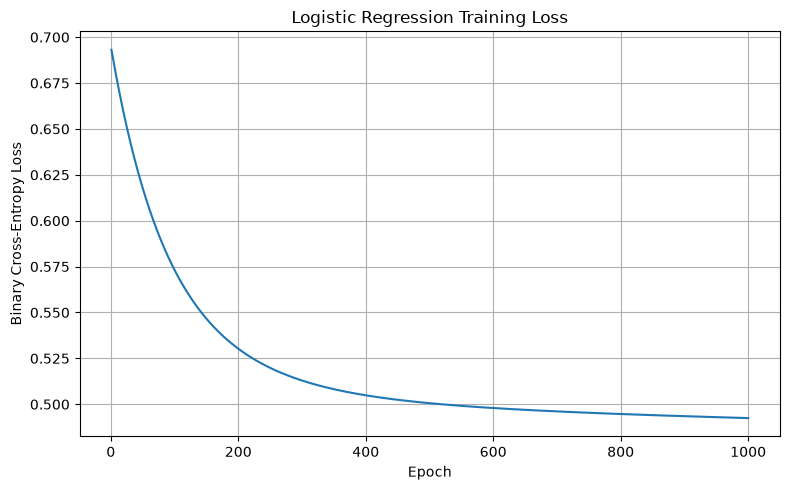

In [63]:

import matplotlib.pyplot as plt

# Plot loss over training epochs
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history)

plt.title("Logistic Regression Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

This shows a steady decrease of the training loss, the model begins to flatten just after 500 epochs, the model makes small improvements as the training continues.

NEXT: IMPROVE TRAINING USING A VALIDATION SET.

In [64]:

from sklearn.model_selection import train_test_split

# Create a validation set from the existing training data
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_array,
    y_train_array,
    test_size=0.20,
    random_state=42,
    stratify=y_train_array
)

print("Subtraining features:", X_subtrain.shape)
print("Validation features:", X_val.shape)

print("\nSubtraining target distribution:")
print(np.unique(y_subtrain, return_counts=True))

print("\nValidation target distribution:")
print(np.unique(y_val, return_counts=True))

Subtraining features: (17056, 109)
Validation features: (4264, 109)

Subtraining target distribution:
(array([0., 1.]), array([13645,  3411]))

Validation target distribution:
(array([0., 1.]), array([3411,  853]))


In [65]:

# Train a fresh model using the subtraining data
val_weights, val_bias, val_loss_history = train_logistic_regression(
    X_subtrain,
    y_subtrain,
    learning_rate=0.01,
    epochs=1000
)

# Predict probabilities for the validation set
z_val = np.dot(X_val, val_weights) + val_bias
y_val_probabilities = sigmoid(z_val)

# Evaluate validation ranking performance
val_roc_auc = roc_auc_score(
    y_val,
    y_val_probabilities
)

print("\nValidation ROC-AUC:", round(val_roc_auc, 4))
print("Final training loss:", round(val_loss_history[-1], 4))


Epoch 100, Loss: 0.5729
Epoch 200, Loss: 0.5299
Epoch 300, Loss: 0.5126
Epoch 400, Loss: 0.5045
Epoch 500, Loss: 0.5002
Epoch 600, Loss: 0.4975
Epoch 700, Loss: 0.4956
Epoch 800, Loss: 0.4942
Epoch 900, Loss: 0.4930
Epoch 1000, Loss: 0.4920

Validation ROC-AUC: 0.5878
Final training loss: 0.492


The validation ROC-AUC is 0.5878 which confirms its ability to distinguish bestsellers from non-bestsellers is still weak.

The training loss decreased to 0.4920, meaning the optimisation is working and so the model is now examined to identify bestsellers at a different classification threshold.

In [66]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Compare classification thresholds on validation data
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

print("Threshold | Precision | Recall | F1-score")
print("------------------------------------------")

for threshold in thresholds:

    # Convert probabilities to class predictions
    val_predictions = (
        y_val_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_val, val_predictions, zero_division=0
    )

    recall = recall_score(
        y_val, val_predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, val_predictions, zero_division=0
    )

    print(
        f"{threshold:9.2f} | "
        f"{precision:9.4f} | "
        f"{recall:6.4f} | "
        f"{f1:8.4f}"
    )


Threshold | Precision | Recall | F1-score
------------------------------------------
     0.20 |    0.2322 | 0.6084 |   0.3361
     0.25 |    0.2832 | 0.3927 |   0.3291
     0.30 |    0.2707 | 0.0727 |   0.1146
     0.35 |    0.1220 | 0.0059 |   0.0112
     0.40 |    0.0000 | 0.0000 |   0.0000
     0.45 |    0.0000 | 0.0000 |   0.0000
     0.50 |    0.0000 | 0.0000 |   0.0000


From these results, it is not noticeable that lowering the threshold increases the recall although the precision remain low. At a threshold of 0.20 the model can successfully identify 0.61% of actual bestsellers, but it also produces false positives.

In [67]:
# Display the 15 largest positive and negative coefficients
coefficients = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Coefficient': val_weights
})

coefficients['Absolute_Coefficient'] = (
    coefficients['Coefficient'].abs()
)

print("Largest positive coefficients:")
print(
    coefficients.sort_values(
        'Coefficient', ascending=False
    ).head(15).to_string(index=False)
)

print("\nLargest negative coefficients:")
print(
    coefficients.sort_values(
        'Coefficient', ascending=True
    ).head(15).to_string(index=False)
)


Largest positive coefficients:
                         Feature  Coefficient  Absolute_Coefficient
                    likedPercent     0.102757              0.102757
                           pages     0.100239              0.100239
                    publish_year     0.087601              0.087601
                          rating     0.018879              0.018879
           bookFormat_Board Book     0.002259              0.002259
            bookFormat_Audiobook     0.001975              0.001975
bookFormat_Mass Market Paperback     0.001846              0.001846
               bookFormat_Comics     0.001578              0.001578
             bookFormat_Audio CD     0.001139              0.001139
               bookFormat_MP3 CD     0.000815              0.000815
            bookFormat_Capa dura     0.000784              0.000784
           bookFormat_Capa comum     0.000404              0.000404
             language_Lithuanian     0.000263              0.000263
        bookForma

In [71]:
val_weights, val_bias, val_loss_history = train_logistic_regression(
    X_subtrain,
    y_subtrain,
    learning_rate=0.01,
    epochs=1000
)

Epoch 100, Loss: 0.5723
Epoch 200, Loss: 0.5297
Epoch 300, Loss: 0.5124
Epoch 400, Loss: 0.5044
Epoch 500, Loss: 0.5001
Epoch 600, Loss: 0.4975
Epoch 700, Loss: 0.4956
Epoch 800, Loss: 0.4942
Epoch 900, Loss: 0.4930
Epoch 1000, Loss: 0.4920


Final validationsubtraining loss after the updated weights and bias.

The loss went from 0.6931 to 0.4920, showing that the model is improving its fits to the training data according to the binary cross-entropy loss function

NEXT: Assess Model's predictions on the validation set

In [72]:
# Predict probabilities for the validation set
val_probabilities = sigmoid(
    np.dot(X_val, val_weights) + val_bias
)

# Classify using the default threshold of 0.5
val_predictions = (val_probabilities >= 0.5).astype(int)

print("Validation results at threshold 0.5")
print("Accuracy:", round(accuracy_score(y_val, val_predictions), 4))
print("Precision:", round(
    precision_score(y_val, val_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_val, val_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_val, val_predictions, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, val_probabilities), 4
))

Validation results at threshold 0.5
Accuracy: 0.8
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5878


These results confirm that the problem remains, even after correcting the loss calculation. The prediction accuracy is 80%, and of the books predicted as best-sellers, none were correctly identified and the model cannot correctly recall none of the actual best-sellers. The model still has a ROC-AUC of 0.59 meaing the model's ability to rank best sellers above non-bestseller is weak.

In [73]:

def train_weighted_logistic_regression(
    X, y, learning_rate=0.01, epochs=1000
):
    m, n = X.shape

    weights = np.zeros(n)
    bias = 0.0
    loss_history = []

    # Calculate class weights from the training data
    negative_count = np.sum(y == 0)
    positive_count = np.sum(y == 1)

    positive_weight = negative_count / positive_count

    sample_weights = np.where(y == 1, positive_weight, 1.0)
    sample_weights = sample_weights / np.mean(sample_weights)

    for epoch in range(epochs):
        # Calculate probabilities
        z = np.dot(X, weights) + bias
        predictions = sigmoid(z)

        # Give greater importance to positive-class errors
        weighted_errors = sample_weights * (predictions - y)

        dw = np.dot(X.T, weighted_errors) / m
        db = np.mean(weighted_errors)

        # Update model parameters
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Record weighted loss after the update
        updated_probabilities = sigmoid(
            np.dot(X, weights) + bias
        )
        updated_probabilities = np.clip(
            updated_probabilities, 1e-15, 1 - 1e-15
        )

        loss = -np.mean(
            sample_weights * (
                y * np.log(updated_probabilities)
                + (1 - y) * np.log(1 - updated_probabilities)
            )
        )

        loss_history.append(loss)

        if (epoch + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1}, "
                f"Weighted Loss: {loss:.4f}"
            )

    return weights, bias, loss_history


In [74]:

weighted_weights, weighted_bias, weighted_loss_history = (
    train_weighted_logistic_regression(
        X_subtrain,
        y_subtrain,
        learning_rate=0.01,
        epochs=1000
    )
)


Epoch 100, Weighted Loss: 0.6850
Epoch 200, Weighted Loss: 0.6793
Epoch 300, Weighted Loss: 0.6751
Epoch 400, Weighted Loss: 0.6718
Epoch 500, Weighted Loss: 0.6692
Epoch 600, Weighted Loss: 0.6670
Epoch 700, Weighted Loss: 0.6651
Epoch 800, Weighted Loss: 0.6635
Epoch 900, Weighted Loss: 0.6621
Epoch 1000, Weighted Loss: 0.6609


In [75]:
# Calculate weighted model probabilities on validation data
weighted_val_probabilities = sigmoid(
    np.dot(X_val, weighted_weights) + weighted_bias
)

# Evaluate at the default threshold of 0.5
weighted_val_predictions = (
    weighted_val_probabilities >= 0.5
).astype(int)

print("Class-weighted model: Validation results")
print("Accuracy:", round(
    accuracy_score(y_val, weighted_val_predictions), 4
))
print("Precision:", round(
    precision_score(
        y_val, weighted_val_predictions, zero_division=0
    ), 4
))
print("Recall:", round(
    recall_score(
        y_val, weighted_val_predictions, zero_division=0
    ), 4
))
print("F1-score:", round(
    f1_score(
        y_val, weighted_val_predictions, zero_division=0
    ), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, weighted_val_probabilities), 4
))
print("Predicted best-sellers:", int(
    weighted_val_predictions.sum()
))
print("Actual best-sellers:", int(y_val.sum()))


Class-weighted model: Validation results
Accuracy: 0.5802
Precision: 0.267
Recall: 0.6295
F1-score: 0.375
ROC-AUC: 0.6461
Predicted best-sellers: 2011
Actual best-sellers: 853


The way in which the Logistic Regression model learns from the training data to address the imbalance between bestseller and non-bestseller was changed. A greater weight was assigned to best-seller examples during training so that errors involving the minority class had more influence on the model's parameter updates and loss function. The model was evaluated on the 0.5 threshold and the model achieved an accuracy of 58.02%, precision of 26.70%, recall 62.95%,an F1-score of 0.375, and a ROC-AUC of 0.6461.

Compared to the original model which had an accuracy of 80% but could not recall any bestseller at 0.5 threshold, the weighted model improved its ability to detect best sellers although there is a trade-off of producing more false false positives.

Next: Test different probability thresholds

In [76]:

# Test different classification thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    predictions = (
        weighted_val_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Predicted best-sellers": int(predictions.sum())
    })

# Display the results
threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-score  Predicted best-sellers
      0.20    0.2045     0.2007  0.9977    0.3341                    4241
      0.25    0.2061     0.2010  0.9977    0.3346                    4234
      0.30    0.2125     0.2023  0.9977    0.3364                    4207
      0.35    0.2355     0.2068  0.9953    0.3425                    4105
      0.40    0.2922     0.2161  0.9660    0.3532                    3813
      0.45    0.4074     0.2314  0.8453    0.3633                    3116
      0.50    0.5802     0.2670  0.6295    0.3750                    2011
      0.55    0.7029     0.3191  0.4279    0.3655                    1144
      0.60    0.7746     0.3821  0.2052    0.2670                     458


The weighted model is tested at different theshold, As the threshold decreases, the model predicts more books as best-sellers. Recall increases, but precision decrease because more non-best-sellers may be incorrectly classified as best-sellers

The threshold from 0.20-0.35, the recall is almost at 100% however the prescion is at 20%, the model predicts almost every book at a bestseller.

Thresholds from 0.40 to 0.45, Recall remains at almost 100%, while precision and F1-score improve.

Threshold 0.55, Accuracy and precision improve, but recall and F1-score decline.

Threshold 0.60:,Accuracy reaches 0.7746, but recall drops to 0.2052. The model misses most actual best-sellers.

In [77]:
# Test a finer range of thresholds
fine_thresholds = np.arange(0.45, 0.551, 0.01)

fine_results = []

for threshold in fine_thresholds:
    predictions = (
        weighted_val_probabilities >= threshold
    ).astype(int)

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

fine_threshold_results = pd.DataFrame(fine_results)

print(
    fine_threshold_results.round(4).to_string(index=False)
)

 Threshold  Precision  Recall  F1-score
      0.45     0.2314  0.8453    0.3633
      0.46     0.2380  0.8101    0.3679
      0.47     0.2448  0.7749    0.3721
      0.48     0.2499  0.7222    0.3713
      0.49     0.2586  0.6753    0.3740
      0.50     0.2670  0.6295    0.3750
      0.51     0.2761  0.5838    0.3749
      0.52     0.2820  0.5451    0.3717
      0.53     0.2949  0.5006    0.3711
      0.54     0.3022  0.4584    0.3642
      0.55     0.3191  0.4279    0.3655


The model is checked at different thresholds before finalising the final threshold to use.
From this experiment, the model works best at a threshold of 0.50 as the provisional classification threshold. 

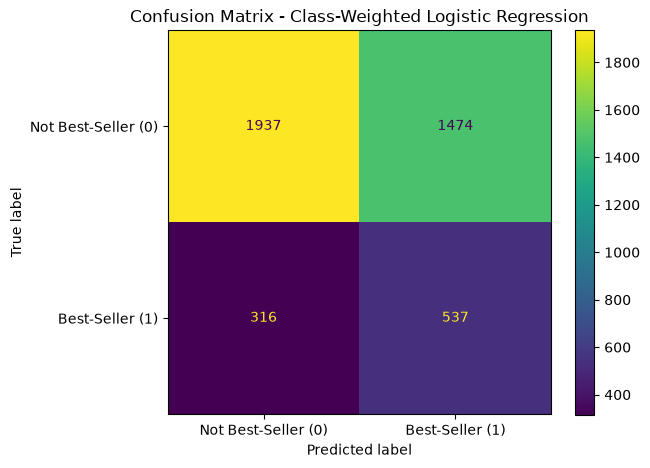

Confusion matrix:
[[1937 1474]
 [ 316  537]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use the selected threshold
selected_threshold = 0.50

# Generate predictions on the validation data
weighted_val_predictions = (
    weighted_val_probabilities >= selected_threshold
).astype(int)

# Calculate the confusion matrix
cm = confusion_matrix(y_val, weighted_val_predictions)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Best-Seller (0)", "Best-Seller (1)"]
)

display.plot(values_format="d")
plt.title("Confusion Matrix - Class-Weighted Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


1937 true negatives, the model correctly identifies 1937 books labelled as non-bestsellers.

1,474 false positives: The model incorrectly classified 1,474 non-best-sellers as best-sellers. This is the largest source of classification errors.

316 false negatives: The model failed to identify 316 actual best-sellers.

537 true positives: The model successfully identified 537 of the 853 actual best-sellers in the validation set.
